In [33]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


# 1. Đọc dữ liệu Train

In [34]:
from pathlib import Path
import inspect
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support
)

# Cấu hình chung
RANDOM_STATE = 42
N_SPLITS = 3
TARGET = "Attack_type"
EXPERIMENT_ID = "B01"

# Xác định thư mục gốc IoT_final
current = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / "project").is_dir()
        and (p / "result").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục IoT_final"
    )

# Đường dẫn Train đã tạo từ C02
TRAIN_PATH = (
    ROOT / "result"
    / "preprocessing"
    / "C02_Data_Splitting_ThanhDai"
    / "data"
    / "processed"
    / "train.csv"
)

# Folder lưu kết quả Baseline
RESULT_DIR = (
    ROOT / "result"
    / "baseline"
    / "B01_MLP_3Fold_ThanhDai"
)

TABLE_DIR = RESULT_DIR / "tables"
IMAGE_DIR = RESULT_DIR / "images"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Đọc dữ liệu
if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy Train: {TRAIN_PATH}"
    )

train_df = pd.read_csv(TRAIN_PATH)

print("=== DỮ LIỆU TRAIN ===")
print("Đường dẫn:", TRAIN_PATH)
print("Kích thước:", train_df.shape)
print("Folder kết quả:", RESULT_DIR)

display(train_df.head(3))

=== DỮ LIỆU TRAIN ===
Đường dẫn: D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\preprocessing\C02_Data_Splitting_ThanhDai\data\processed\train.csv
Kích thước: (82536, 83)
Folder kết quả: D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\baseline\B01_MLP_3Fold_ThanhDai


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,64177,46532,udp,-,0.000000,1,0,1,0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NMAP_UDP_SCAN
1,20209,21,tcp,-,0.000005,1,1,1,0,199728.761905,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
2,3694,21,tcp,-,0.000005,1,1,1,0,199728.761905,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping


### Nhận xét: Đọc dữ liệu Train

**Kết quả:**

- Sử dụng tập Train được tạo từ C02_Data_Splitting_ThanhDai.
- Tập Train chiếm khoảng 70% dữ liệu sau Cleaning.
- Nhãn mục tiêu là `Attack_type`.
- Dữ liệu chưa được chuẩn hóa hoặc mã hóa trước khi chia fold.

**Kết luận:**

Đã chuẩn bị dữ liệu đầu vào để thực hiện
3-fold Cross-Validation cho MLP Baseline.

# 2. Tách đặc trưng, nhãn và kiểm tra dữ liệu

In [35]:
DROP_COLS = [
    TARGET,
    "Unnamed: 0",
    "group_id"
]

# Tách đặc trưng và nhãn
X = train_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y = train_df[TARGET].astype(str).copy()

# Các đặc trưng phân loại
categorical_features = [
    "proto",
    "service"
]

# Kiểm tra cột phân loại
missing_categories = [
    c for c in categorical_features
    if c not in X.columns
]

if missing_categories:
    raise ValueError(
        f"Thiếu đặc trưng phân loại: {missing_categories}"
    )

# Các đặc trưng dạng số
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Kiểm tra kiểu dữ liệu
if set(categorical_features + numeric_features) != set(X.columns):
    raise ValueError(
        "Có đặc trưng không thuộc nhóm số hoặc phân loại"
    )

# Kiểm tra Missing Values
if X.isna().any().any() or y.isna().any():
    raise ValueError(
        "Dữ liệu Train có giá trị thiếu"
    )

# Kiểm tra Inf
if not np.isfinite(
    X[numeric_features].to_numpy()
).all():
    raise ValueError(
        "Đặc trưng số chứa giá trị vô hạn"
    )

# Kiểm tra phân bố nhãn
LABELS = sorted(y.unique().tolist())

class_counts = y.value_counts().sort_values()

if class_counts.min() < N_SPLITS:
    raise ValueError(
        "Có lớp ít hơn 3 mẫu, không đủ chia 3-fold"
    )

print("=== THÔNG TIN ĐẦU VÀO ===")

print("Số mẫu:", len(X))
print("Số đặc trưng:", X.shape[1])
print("Đặc trưng số:", len(numeric_features))
print("Đặc trưng phân loại:", len(categorical_features))
print("Số nhãn:", len(LABELS))

print("\n=== PHÂN BỐ NHÃN ===")

display(
    class_counts.rename("Số mẫu").to_frame()
)

print("\nLớp ít mẫu nhất:")
print(class_counts.index[0], ":", class_counts.iloc[0])

=== THÔNG TIN ĐẦU VÀO ===
Số mẫu: 82536
Số đặc trưng: 82
Đặc trưng số: 80
Đặc trưng phân loại: 2
Số nhãn: 12

=== PHÂN BỐ NHÃN ===


,Số mẫu
Attack_type,
NMAP_FIN_SCAN,20
Metasploit_Brute_Force_SSH,25
Wipro_bulb,153
DDOS_Slowloris,373
NMAP_TCP_scan,701
NMAP_OS_DETECTION,1400
NMAP_XMAS_TREE_SCAN,1407
NMAP_UDP_SCAN,1807
MQTT_Publish,2899



Lớp ít mẫu nhất:
NMAP_FIN_SCAN : 20


### Nhận xét: Chuẩn bị dữ liệu

**Kết quả:**

- Đã tách nhãn `Attack_type` khỏi đặc trưng đầu vào.
- Hai đặc trưng phân loại là `proto` và `service`.
- Các đặc trưng còn lại có dạng số.
- Không phát hiện giá trị thiếu hoặc vô hạn.
- Các lớp đều có đủ số mẫu để thực hiện 3-fold CV.

**Kết luận:**

Dữ liệu có thể đưa vào Pipeline gồm
StandardScaler, OneHotEncoder và MLPClassifier.

# 3. Xây dưng Pipeline MLP Baseline

In [36]:
def make_pipeline():

    # Hỗ trợ các phiên bản scikit-learn khác nhau
    ohe_args = {
        "handle_unknown": "ignore"
    }

    if "sparse_output" in inspect.signature(
        OneHotEncoder
    ).parameters:
        ohe_args["sparse_output"] = False
    else:
        ohe_args["sparse"] = False

    # Tiền xử lý
    preprocess = ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(**ohe_args),
                categorical_features
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )

    # Mô hình MLP
    mlp = MLPClassifier(
        hidden_layer_sizes=(64,),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        batch_size=512,
        max_iter=60,
        n_iter_no_change=8,
        early_stopping=False,
        random_state=RANDOM_STATE,
        verbose=False
    )

    # Kết hợp tiền xử lý và mô hình
    return Pipeline([
        ("preprocess", preprocess),
        ("model", mlp)
    ])


# 5 chỉ số dùng trong Excel nhóm
METRICS = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]


# Hàm đánh giá mô hình
def evaluate(y_true, y_pred):

    return {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0
        ),

        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }


print("=== PIPELINE MLP BASELINE ===")
print(make_pipeline())

=== PIPELINE MLP BASELINE ===
Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric', StandardScaler(),
                                                  ['id.orig_p', 'id.resp_p',
                                                   'flow_duration',
                                                   'fwd_pkts_tot',
                                                   'bwd_pkts_tot',
                                                   'fwd_data_pkts_tot',
                                                   'bwd_data_pkts_tot',
                                                   'fwd_pkts_per_sec',
                                                   'bwd_pkts_per_sec',
                                                   'flow_pkts_per_sec',
                                                   'down_up_ratio',
                                                   'fwd_header_size_tot',
                          

### Nhận xét: Xây dựng MLP Baseline

**Cấu hình mô hình:**

- MLP gồm một lớp ẩn với 64 neuron.
- Hàm kích hoạt ReLU.
- Bộ tối ưu Adam.
- Learning rate = 0.001.
- Alpha = 0.0001.
- Batch size = 512.
- Số epoch tối đa = 60.
- Không sử dụng Early Stopping.

**Phương pháp tiền xử lý:**

- StandardScaler cho đặc trưng số.
- OneHotEncoder cho `proto` và `service`.

**Ý nghĩa:**

Pipeline đảm bảo các tham số tiền xử lý
được học trên phần Train của từng fold.

Mỗi lần huấn luyện tạo một Pipeline mới,
không sử dụng lại trạng thái của fold trước.

**Kết luận:**

Đã xây dựng cấu hình MLP Baseline để thực hiện
3-fold Cross-Validation.

# 4. Huấn luyện MLP bằng 3-fold Cross-Validation

In [37]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Lưu kết quả từng fold
fold_rows = []

# Lưu đánh giá từng lớp
class_rows = []

# Lưu Training Loss
loss_curves = {}

for fold, (train_idx, cv_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    print("\n" + "=" * 50)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 50)

    # Chia dữ liệu trong từng fold
    X_fit = X.iloc[train_idx]
    y_fit = y.iloc[train_idx]

    X_cv = X.iloc[cv_idx]
    y_cv = y.iloc[cv_idx]

    # Mỗi fold tạo Pipeline mới
    model = make_pipeline()

    # Đo thời gian huấn luyện
    started = time.perf_counter()

    # Fit tiền xử lý và MLP trên phần Train của fold
    model.fit(X_fit, y_fit)

    seconds = time.perf_counter() - started

    # Dự đoán trên fold kiểm định
    pred_cv = model.predict(X_cv)

    # Dự đoán trên phần Train để kiểm tra Overfitting
    pred_fit = model.predict(X_fit)

    # Tính điểm
    scores = evaluate(y_cv, pred_cv)
    train_scores = evaluate(y_fit, pred_fit)

    # Lấy thông tin huấn luyện MLP
    mlp = model.named_steps["model"]

    # Lưu Loss từng epoch
    loss_curves[fold] = list(mlp.loss_curve_)

    # Ghi kết quả fold
    fold_rows.append({
        "fold": fold,
        "n_fit": len(X_fit),
        "n_cv": len(X_cv),
        "fit_seconds": seconds,
        "epochs": mlp.n_iter_,
        "final_train_loss": float(mlp.loss_),
        **scores,
        **{
            f"train_{k}": v
            for k, v in train_scores.items()
        }
    })

    # Tính Precision / Recall / F1 cho từng lớp
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_cv,
            pred_cv,
            labels=LABELS,
            zero_division=0
        )
    )

    for lab, sup, p, r, f in zip(
        LABELS,
        support,
        precision,
        recall,
        f1
    ):
        class_rows.append({
            "fold": fold,
            "class": lab,
            "support": int(sup),
            "precision": float(p),
            "recall": float(r),
            "f1": float(f)
        })

    # In kết quả từng fold
    print(f"Số mẫu Train: {len(X_fit):,}")
    print(f"Số mẫu CV: {len(X_cv):,}")
    print(f"Số epoch thực tế: {mlp.n_iter_}")
    print(f"Thời gian: {seconds:.2f} giây")

    print("\n=== 5 CHỈ SỐ ĐÁNH GIÁ ===")

    for metric in METRICS:
        print(
            f"{metric:18s}: {scores[metric]:.6f}"
        )

# Tổng hợp kết quả
cv_results = pd.DataFrame(fold_rows)

per_class_results = pd.DataFrame(class_rows)

print("\n" + "=" * 50)
print("KẾT QUẢ CỦA CẢ 3 FOLD")
print("=" * 50)

display(
    cv_results[
        ["fold", *METRICS, "fit_seconds", "epochs"]
    ].round(6)
)


FOLD 1/3


d:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


Số mẫu Train: 55,024
Số mẫu CV: 27,512
Số epoch thực tế: 60
Thời gian: 9.16 giây

=== 5 CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.995893
macro_f1          : 0.950112
weighted_f1       : 0.995897
macro_precision   : 0.975617
macro_recall      : 0.933747

FOLD 2/3


d:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


Số mẫu Train: 55,024
Số mẫu CV: 27,512
Số epoch thực tế: 60
Thời gian: 8.95 giây

=== 5 CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.995347
macro_f1          : 0.934190
weighted_f1       : 0.995279
macro_precision   : 0.972562
macro_recall      : 0.911892

FOLD 3/3


d:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


Số mẫu Train: 55,024
Số mẫu CV: 27,512
Số epoch thực tế: 60
Thời gian: 15.25 giây

=== 5 CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.995457
macro_f1          : 0.953476
weighted_f1       : 0.995522
macro_precision   : 0.940582
macro_recall      : 0.970012

KẾT QUẢ CỦA CẢ 3 FOLD


,fold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,fit_seconds,epochs
0,1,0.995893,0.950112,0.995897,0.975617,0.933747,9.164392,60
1,2,0.995347,0.934190,0.995279,0.972562,0.911892,8.951372,60
2,3,0.995457,0.953476,0.995522,0.940582,0.970012,15.245633,60


### Nhận xét: Huấn luyện 3-fold CV

**Quy trình huấn luyện:**

- Sử dụng StratifiedKFold với 3 fold.
- Ở mỗi lượt, mô hình được huấn luyện trên 2 fold
  và đánh giá trên fold còn lại.
- Quá trình được thực hiện 3 lần để mỗi phần
  dữ liệu được sử dụng làm tập kiểm định một lần.
- Mỗi fold sử dụng cùng cấu hình MLP Baseline.

**Chỉ số đánh giá:**

1. Accuracy: Tỷ lệ dự đoán chính xác.
2. Macro-F1: Trung bình F1 của các lớp,
   không phụ thuộc vào số mẫu mỗi lớp.
3. Weighted-F1: Trung bình F1 có trọng số
   theo số mẫu của từng lớp.
4. Macro-Precision: Trung bình Precision
   của các lớp.
5. Macro-Recall: Trung bình Recall
   của các lớp.

**Ý nghĩa:**

Do dataset có 12 lớp và mất cân bằng mạnh,
Macro-F1 được sử dụng làm chỉ số chính.

Kết quả của từng fold giúp đánh giá
mức độ ổn định của mô hình khi thay đổi
phần dữ liệu huấn luyện và kiểm định.

**Kết luận:**

Đã xây dựng quy trình huấn luyện và đánh giá
MLP Baseline bằng 3-fold Cross-Validation.

# 5. Tổng hợp điểm của 3-fold và xuất bảng Excel

In [38]:
summary = pd.DataFrame({

    "metric": METRICS,

    "cv_mean": [
        cv_results[m].mean()
        for m in METRICS
    ],

    "cv_std": [
        cv_results[m].std(ddof=1)
        for m in METRICS
    ],

    "train_mean": [
        cv_results[f"train_{m}"].mean()
        for m in METRICS
    ]
})

# Tính chênh lệch Train - CV
summary["train_cv_gap"] = (
    summary["train_mean"] - summary["cv_mean"]
)

print("=== KẾT QUẢ TRUNG BÌNH 3-FOLD CV ===")

display(summary.round(6))

# In Macro-F1
macro = (
    summary.set_index("metric")
    .loc["macro_f1"]
)

print("\n=== ĐÁNH GIÁ MACRO-F1 ===")

print(
    f"CV Macro-F1 trung bình: "
    f"{macro['cv_mean']:.6f}"
)

print(
    f"Độ lệch chuẩn: "
    f"{macro['cv_std']:.6f}"
)

print(
    f"Chênh lệch Train - CV: "
    f"{macro['train_cv_gap']:.6f}"
)

# Lưu kết quả
cv_results.to_csv(
    TABLE_DIR / "B01_cv_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    TABLE_DIR / "B01_cv_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

per_class_results.to_csv(
    TABLE_DIR / "B01_cv_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. XUẤT EXCEL KẾT QUẢ 3-FOLD CV

from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

OUTPUT_EXCEL = RESULT_DIR / "B01_MLP_3Fold_KetQua.xlsx"

# Tạo workbook mới
wb = Workbook()
ws = wb.active
ws.title = "MLP - B01"

# ========================================
# 1. TIÊU ĐỀ
# ========================================

ws.merge_cells("A1:Z1")
ws["A1"] = "MÔ HÌNH: MLP BASELINE"

# ========================================
# 2. NHÓM CỘT
# ========================================

groups = {
    "A2:D2": "Thông tin thực nghiệm",
    "E2:I2": "Lượt 1",
    "J2:N2": "Lượt 2",
    "O2:S2": "Lượt 3",
    "T2:X2": "Valid"
}

for cell_range, title in groups.items():
    ws.merge_cells(cell_range)
    first_cell = cell_range.split(":")[0]
    ws[first_cell] = title

ws.merge_cells("Y2:Z2")
ws["Y2"] = "Nhận xét"

# ========================================
# 3. TÊN CỘT
# ========================================

metric_headers = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]

headers = [
    "MÃ",
    "MÃ SO SÁNH",
    "Xử lý dữ liệu",
    "Thông số model",
    *metric_headers,
    *metric_headers,
    *metric_headers,
    *metric_headers,
    "Điểm yếu",
    "Đã khắc phục"
]

for col, header in enumerate(headers, start=1):
    ws.cell(row=3, column=col, value=header)

# ========================================
# 4. THÔNG TIN BASELINE
# ========================================

ws["A4"] = "B01 (MLP Baseline)"
ws["B4"] = ""
ws["C4"] = "StandardScaler + OneHotEncoder"

ws["D4"] = (
    "hidden_layer_sizes=(64,), "
    "activation=relu, solver=adam, "
    "alpha=0.0001, learning_rate_init=0.001, "
    "batch_size=512, max_iter=60, "
    "n_iter_no_change=8, "
    "early_stopping=False, random_state=42"
)

# ========================================
# 5. GHI KẾT QUẢ 3 FOLD
# ========================================

scores_by_fold = cv_results.set_index("fold")

for fold in range(1, 4):

    start_col = 5 + (fold - 1) * 5

    for i, metric in enumerate(metric_headers):

        score = float(
            scores_by_fold.loc[fold, metric]
        )

        cell = ws.cell(
            row=4,
            column=start_col + i
        )

        cell.value = score
        cell.number_format = "0.000000"

# Các ô T4:X4 (Valid) để trống

ws["Y4"] = "Chưa phân tích điểm yếu cuối cùng"
ws["Z4"] = "Chưa thực hiện cải tiến"

# ========================================
# 6. ĐỊNH DẠNG EXCEL
# ========================================

ws.sheet_view.showGridLines = False

# Tiêu đề chính
ws["A1"].font = Font(
    size=14,
    bold=True
)

ws["A1"].alignment = Alignment(
    horizontal="center",
    vertical="center"
)

ws.row_dimensions[1].height = 32

# Định dạng hàng nhóm và tiêu đề cột
for row in [2, 3]:
    for cell in ws[row]:

        cell.fill = PatternFill(
            "solid",
            fgColor="DCEAF7" if row == 2 else "E8EEF4"
        )

        cell.font = Font(bold=True)

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True
        )

ws.row_dimensions[2].height = 26
ws.row_dimensions[3].height = 40
ws.row_dimensions[4].height = 75

# Độ rộng cột
widths = {
    "A": 20,
    "B": 18,
    "C": 35,
    "D": 60,
    "Y": 32,
    "Z": 32
}

for col, width in widths.items():
    ws.column_dimensions[col].width = width

for col in range(5, 25):
    ws.column_dimensions[
        get_column_letter(col)
    ].width = 17

# Căn giữa điểm số và xuống dòng nội dung
for row in ws.iter_rows(min_row=4, max_row=4):

    for cell in row:

        cell.alignment = Alignment(
            horizontal="center" if 5 <= cell.column <= 24 else "left",
            vertical="center",
            wrap_text=True
        )

# Viền bảng
thin_border = Border(
    left=Side(style="thin", color="D1D5DB"),
    right=Side(style="thin", color="D1D5DB"),
    top=Side(style="thin", color="D1D5DB"),
    bottom=Side(style="thin", color="D1D5DB")
)

for row in ws.iter_rows(
    min_row=3,
    max_row=4,
    min_col=1,
    max_col=26
):
    for cell in row:
        cell.border = thin_border

# Cố định tiêu đề và 4 cột thông tin
ws.freeze_panes = "E4"

# ========================================
# 7. LƯU FILE
# ========================================

wb.save(OUTPUT_EXCEL)

print("ĐÃ XUẤT EXCEL THÀNH CÔNG!")
print("Đường dẫn:", OUTPUT_EXCEL)

=== KẾT QUẢ TRUNG BÌNH 3-FOLD CV ===


,metric,cv_mean,cv_std,train_mean,train_cv_gap
0,accuracy,0.995566,0.000289,0.996704,0.001139
1,macro_f1,0.945926,0.010302,0.963570,0.017644
2,weighted_f1,0.995566,0.000312,0.996712,0.001146
3,macro_precision,0.962920,0.019406,0.982544,0.019624
4,macro_recall,0.938550,0.029356,0.950428,0.011878



=== ĐÁNH GIÁ MACRO-F1 ===
CV Macro-F1 trung bình: 0.945926
Độ lệch chuẩn: 0.010302
Chênh lệch Train - CV: 0.017644
ĐÃ XUẤT EXCEL THÀNH CÔNG!
Đường dẫn: D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\baseline\B01_MLP_3Fold_ThanhDai\B01_MLP_3Fold_KetQua.xlsx


### Nhận xét: Tổng hợp kết quả 3-fold CV

**Ý nghĩa:**

Điểm Macro-F1 trung bình phản ánh khả năng
phân loại chung của mô hình trên các fold.

Độ lệch chuẩn càng nhỏ cho thấy điểm số
ít dao động giữa các lượt kiểm định,
nhưng không tự chứng minh mô hình sẽ tổng quát tốt.

Nếu điểm Train cao hơn điểm CV đáng kể,
mô hình có thể xuất hiện dấu hiệu Overfitting.

**Kết luận:**

Kết quả 3-fold CV là cơ sở để đánh giá
MLP Baseline trước khi chuyển sang
Validation và các thực nghiệm cải tiến.

# 6. Vẽ Training Loss và phân tích các lớp dự đoán kém

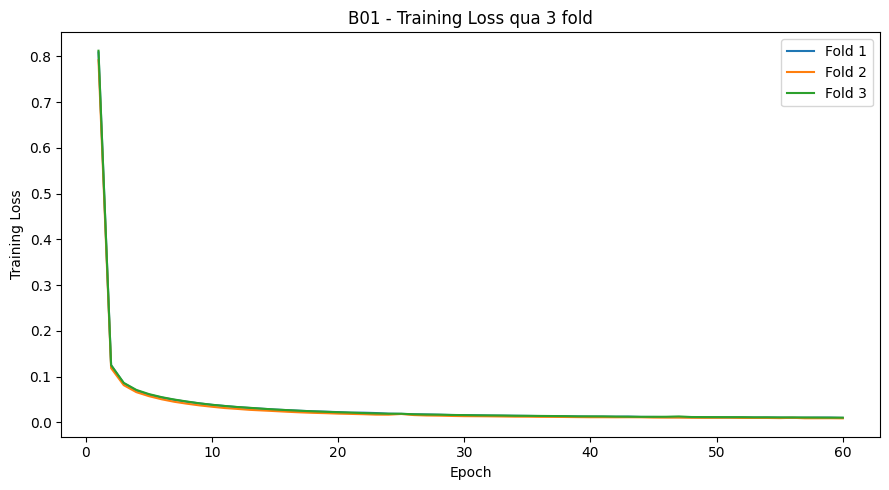


=== ĐÁNH GIÁ THEO TỪNG LỚP ===


,class,mean_f1,std_f1,mean_recall,total_cv_support
4,Metasploit_Brute_Force_SSH,0.810458,0.137721,0.754630,25
5,NMAP_FIN_SCAN,0.863492,0.066893,0.841270,20
1,DDOS_Slowloris,0.877522,0.013337,0.917226,373
11,Wipro_bulb,0.882535,0.032009,0.843137,153
8,NMAP_UDP_SCAN,0.967096,0.003569,0.952965,1807
0,ARP_poisioning,0.978602,0.002573,0.981815,5334
10,Thing_Speak,0.979747,0.001311,0.980019,5355
7,NMAP_TCP_scan,0.995720,0.002141,0.995726,701
3,MQTT_Publish,0.998100,0.001665,0.997239,2899
6,NMAP_OS_DETECTION,0.998573,0.000619,1.000000,1400



=== 5 LỚP CÓ F1 THẤP NHẤT ===


,class,mean_f1,std_f1,mean_recall,total_cv_support
4,Metasploit_Brute_Force_SSH,0.810458,0.137721,0.754630,25
5,NMAP_FIN_SCAN,0.863492,0.066893,0.841270,20
1,DDOS_Slowloris,0.877522,0.013337,0.917226,373
11,Wipro_bulb,0.882535,0.032009,0.843137,153
8,NMAP_UDP_SCAN,0.967096,0.003569,0.952965,1807



Đã lưu biểu đồ tại:
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\baseline\B01_MLP_3Fold_ThanhDai\images\B01_3fold_training_loss.png


In [39]:
# 6.1. Vẽ Training Loss của 3 fold
plt.figure(figsize=(9, 5))

for fold, losses in loss_curves.items():

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Fold {fold}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("B01 - Training Loss qua 3 fold")

plt.legend()
plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "B01_3fold_training_loss.png",
    dpi=160
)

plt.show()


# 6.2. Tổng hợp kết quả theo từng lớp
class_summary = (
    per_class_results
    .groupby("class", as_index=False)
    .agg(
        mean_f1=("f1", "mean"),
        std_f1=("f1", "std"),
        mean_recall=("recall", "mean"),
        total_cv_support=("support", "sum")
    )
    .sort_values("mean_f1")
)

print("\n=== ĐÁNH GIÁ THEO TỪNG LỚP ===")

display(class_summary.round(6))

# 6.3. Lưu bảng
class_summary.to_csv(
    TABLE_DIR / "B01_cv_per_class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== 5 LỚP CÓ F1 THẤP NHẤT ===")

display(
    class_summary.head(5).round(6)
)

print("\nĐã lưu biểu đồ tại:")
print(IMAGE_DIR / "B01_3fold_training_loss.png")

### Nhận xét: Training Loss và kết quả từng lớp

**1. Biểu đồ Training Loss**

Biểu đồ thể hiện sự thay đổi của hàm mất mát
trong quá trình huấn luyện MLP ở 3 fold.

**2. Đánh giá theo từng lớp**

Bảng kết quả cho biết:

- Mean F1: Điểm F1 trung bình của từng lớp.
- Std F1: Mức dao động F1 giữa các fold.
- Mean Recall: Khả năng nhận diện trung bình
  của từng lớp.
- Total CV Support: Tổng số mẫu dùng để kiểm định
  của từng lớp qua 3 fold.

**Kết luận:**

Kết quả phân tích từng lớp giúp xác định
những điểm yếu của MLP Baseline.

Đây là căn cứ để đề xuất các phương pháp
cải tiến trong giai đoạn thực nghiệm.

# 7. Đọc tập Validation

In [40]:
VALID_PATH = (
    ROOT / "result"
    / "preprocessing"
    / "C02_Data_Splitting_ThanhDai"
    / "data"
    / "processed"
    / "validation.csv"
)

if not VALID_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy Validation: {VALID_PATH}"
    )

valid_df = pd.read_csv(VALID_PATH)

# Tách đặc trưng và nhãn
X_valid = valid_df.drop(
    columns=[
        TARGET,
        "Unnamed: 0",
        "group_id"
    ],
    errors="ignore"
).copy()

y_valid = valid_df[TARGET].astype(str).copy()

# Đảm bảo Train và Validation có cùng đặc trưng
if set(X.columns) != set(X_valid.columns):
    raise ValueError(
        "Train và Validation không cùng danh sách đặc trưng"
    )

# Sắp xếp đúng thứ tự cột của Train
X_valid = X_valid[X.columns]

# Kiểm tra giá trị thiếu
assert not X_valid.isna().any().any()
assert not y_valid.isna().any()

# Kiểm tra giá trị vô hạn
assert np.isfinite(
    X_valid[numeric_features].to_numpy()
).all()

# Kiểm tra nhãn
assert set(y_valid.unique()).issubset(set(LABELS))

print("=== THÔNG TIN VALIDATION ===")

print("Kích thước:", valid_df.shape)
print("Số mẫu:", len(X_valid))
print("Số đặc trưng:", X_valid.shape[1])
print("Số lớp:", y_valid.nunique())

print("\n=== PHÂN BỐ NHÃN VALIDATION ===")

display(
    y_valid.value_counts()
    .rename("Số mẫu")
    .to_frame()
)

print("\nKiểm tra Validation thành công!")

=== THÔNG TIN VALIDATION ===
Kích thước: (17687, 83)
Số mẫu: 17687
Số đặc trưng: 82
Số lớp: 12

=== PHÂN BỐ NHÃN VALIDATION ===


,Số mẫu
Attack_type,
DOS_SYN_Hping,13514
Thing_Speak,1148
ARP_poisioning,1143
MQTT_Publish,622
NMAP_UDP_SCAN,388
NMAP_XMAS_TREE_SCAN,301
NMAP_OS_DETECTION,300
NMAP_TCP_scan,150
DDOS_Slowloris,79



Kiểm tra Validation thành công!


### Nhận xét: Chuẩn bị Validation

**Kết quả:**

- Đã đọc tập Validation được tạo từ C02.
- Validation có cùng danh sách đặc trưng với Train.
- Đã tách nhãn `Attack_type` khỏi dữ liệu đầu vào.
- Đã kiểm tra giá trị thiếu, vô hạn và các nhãn xuất hiện.

**Kết luận:**

Validation được chuẩn bị để đánh giá mô hình
sau khi huấn luyện trên toàn bộ Train.

# 8. Huấn luyện trên toàn bộ Train và đánh giá Validation

In [41]:
# Tạo Pipeline mới từ cấu hình Baseline
final_model = make_pipeline()

print("=== HUẤN LUYỆN TRÊN TOÀN BỘ TRAIN ===")

print("Số mẫu Train:", len(X))
print("Số mẫu Validation:", len(X_valid))

# Bắt đầu huấn luyện
start_time = time.perf_counter()

final_model.fit(X, y)

training_time = time.perf_counter() - start_time

# Dự đoán Train
y_train_pred = final_model.predict(X)

# Dự đoán Validation
y_valid_pred = final_model.predict(X_valid)

# Đánh giá
train_metrics = evaluate(y, y_train_pred)

valid_metrics = evaluate(y_valid, y_valid_pred)

# Thông tin quá trình huấn luyện
final_mlp = final_model.named_steps["model"]

print("\n=== THÔNG TIN HUẤN LUYỆN ===")

print(f"Thời gian: {training_time:.2f} giây")
print(f"Số epoch: {final_mlp.n_iter_}")
print(f"Training Loss cuối: {final_mlp.loss_:.6f}")

# Tổng hợp 5 chỉ số
validation_comparison = pd.DataFrame({
    "metric": METRICS,
    "train": [train_metrics[m] for m in METRICS],
    "validation": [valid_metrics[m] for m in METRICS]
})

validation_comparison["train_valid_gap"] = (
    validation_comparison["train"]
    - validation_comparison["validation"]
)

print("\n=== KẾT QUẢ ĐÁNH GIÁ ===")

display(validation_comparison.round(6))

print("\n=== 5 CHỈ SỐ VALIDATION ===")

for metric in METRICS:
    print(f"{metric:18s}: {valid_metrics[metric]:.6f}")

=== HUẤN LUYỆN TRÊN TOÀN BỘ TRAIN ===
Số mẫu Train: 82536
Số mẫu Validation: 17687


d:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(



=== THÔNG TIN HUẤN LUYỆN ===
Thời gian: 23.42 giây
Số epoch: 60
Training Loss cuối: 0.009141

=== KẾT QUẢ ĐÁNH GIÁ ===


,metric,train,validation,train_valid_gap
0,accuracy,0.996729,0.995929,0.000799
1,macro_f1,0.963974,0.965450,-0.001476
2,weighted_f1,0.996683,0.995880,0.000803
3,macro_precision,0.992925,0.985485,0.007440
4,macro_recall,0.940841,0.949279,-0.008439



=== 5 CHỈ SỐ VALIDATION ===
accuracy          : 0.995929
macro_f1          : 0.965450
weighted_f1       : 0.995880
macro_precision   : 0.985485
macro_recall      : 0.949279


### Nhận xét: Huấn luyện lại và đánh giá Validation

**Quy trình:**

- Tạo một Pipeline MLP mới.
- Huấn luyện lại trên toàn bộ tập Train.
- Sử dụng cấu hình Baseline giống 3-fold CV.
- Dự đoán trên Train và Validation.
- Tính Accuracy, Macro-F1, Weighted-F1,
  Macro-Precision và Macro-Recall.

**Ý nghĩa kết quả:**

- Điểm Train phản ánh hiệu quả trên dữ liệu
  đã được mô hình sử dụng để học.
- Điểm Validation phản ánh khả năng dự đoán
  trên tập dữ liệu độc lập với Train.
- Chênh lệch Train - Validation giúp xem xét
  dấu hiệu Overfitting.

**Kết luận:**

Đã xây dựng bước đánh giá Validation cho
MLP Baseline mà không thay đổi cấu hình mô hình.

# 9. Confusion Matrix và đánh giá từng lớp

=== KẾT QUẢ VALIDATION THEO TỪNG LỚP ===


,class,precision,recall,f1,support
0,DDOS_Slowloris,0.984375,0.797468,0.881119,79
1,Metasploit_Brute_Force_SSH,1.000000,0.800000,0.888889,5
2,Wipro_bulb,0.933333,0.848485,0.888889,33
3,NMAP_UDP_SCAN,0.959900,0.987113,0.973316,388
4,ARP_poisioning,0.972366,0.985127,0.978705,1143
5,Thing_Speak,0.982472,0.976481,0.979467,1148
6,NMAP_TCP_scan,0.993377,1.000000,0.996678,150
7,NMAP_XMAS_TREE_SCAN,1.000000,0.996678,0.998336,301
8,NMAP_OS_DETECTION,1.000000,1.000000,1.000000,300
9,NMAP_FIN_SCAN,1.000000,1.000000,1.000000,4



=== 5 LỚP CÓ F1 THẤP NHẤT ===


,class,precision,recall,f1,support
0,DDOS_Slowloris,0.984375,0.797468,0.881119,79
1,Metasploit_Brute_Force_SSH,1.000000,0.800000,0.888889,5
2,Wipro_bulb,0.933333,0.848485,0.888889,33
3,NMAP_UDP_SCAN,0.959900,0.987113,0.973316,388
4,ARP_poisioning,0.972366,0.985127,0.978705,1143


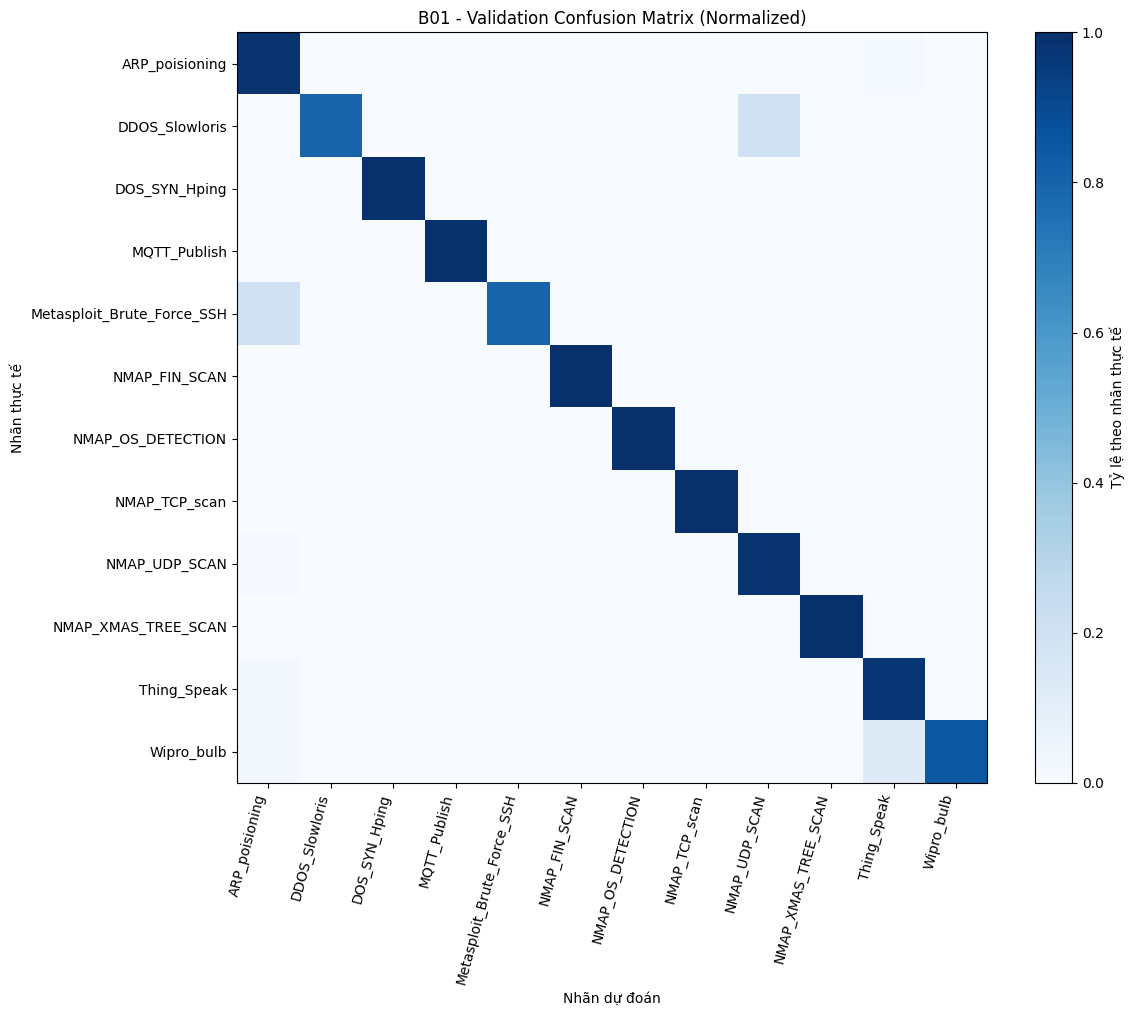

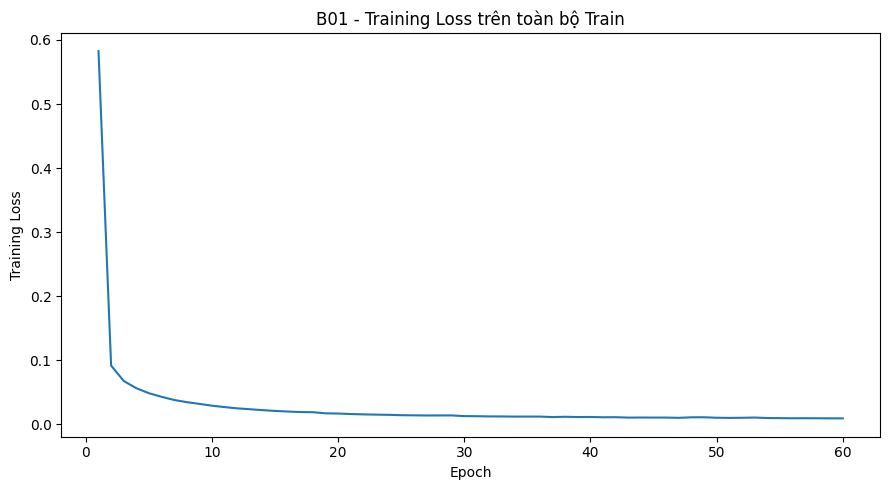


Đã lưu bảng và biểu đồ Validation!


In [42]:
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support
)

# Tính Precision, Recall, F1 từng lớp
precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_valid,
        y_valid_pred,
        labels=LABELS,
        zero_division=0
    )
)

per_class_valid = pd.DataFrame({
    "class": LABELS,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support
})

# Sắp xếp theo F1 tăng dần
per_class_valid = per_class_valid.sort_values(
    "f1"
).reset_index(drop=True)

print("=== KẾT QUẢ VALIDATION THEO TỪNG LỚP ===")

display(per_class_valid.round(6))

print("\n=== 5 LỚP CÓ F1 THẤP NHẤT ===")

display(per_class_valid.head(5).round(6))

# Confusion Matrix
cm = confusion_matrix(
    y_valid,
    y_valid_pred,
    labels=LABELS
)

# Chuẩn hóa theo số mẫu thực tế của từng lớp
cm_normalized = np.divide(
    cm,
    cm.sum(axis=1, keepdims=True),
    out=np.zeros_like(cm, dtype=float),
    where=cm.sum(axis=1, keepdims=True) != 0
)

# Vẽ Confusion Matrix
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))

ax.set_xticklabels(
    LABELS,
    rotation=75,
    ha="right"
)

ax.set_yticklabels(LABELS)

ax.set_xlabel("Nhãn dự đoán")
ax.set_ylabel("Nhãn thực tế")

ax.set_title(
    "B01 - Validation Confusion Matrix (Normalized)"
)

fig.colorbar(
    im,
    ax=ax,
    label="Tỷ lệ theo nhãn thực tế"
)

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "B01_validation_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Vẽ Training Loss của mô hình cuối
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(final_mlp.loss_curve_) + 1),
    final_mlp.loss_curve_
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("B01 - Training Loss trên toàn bộ Train")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "B01_full_train_loss.png",
    dpi=160
)

plt.show()

# Lưu kết quả chi tiết
per_class_valid.to_csv(
    TABLE_DIR / "B01_validation_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(
    cm,
    index=LABELS,
    columns=LABELS
).to_csv(
    TABLE_DIR / "B01_validation_confusion_matrix.csv",
    encoding="utf-8-sig"
)

validation_comparison.to_csv(
    TABLE_DIR / "B01_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu bảng và biểu đồ Validation!")

### Nhận xét: Confusion Matrix và từng lớp

**Confusion Matrix:**

- Các ô trên đường chéo thể hiện những mẫu
  được mô hình phân loại chính xác.
- Các ô ngoài đường chéo thể hiện những mẫu
  bị phân loại nhầm.
- Confusion Matrix được chuẩn hóa theo từng
  lớp thực tế để dễ quan sát các lớp ít mẫu.

**Training Loss:**

Biểu đồ cho thấy quá trình tối ưu trên Train.

Training Loss giảm không đồng nghĩa với
khả năng tổng quát hóa tốt. Cần đối chiếu
với các chỉ số Validation.

**Kết luận:**

Kết quả đánh giá theo từng lớp và Confusion
Matrix là căn cứ xác định điểm yếu của
MLP Baseline trước các thực nghiệm cải tiến.

# 10. Điền kết quả Validation vào Excel

In [43]:
from openpyxl import load_workbook

EXCEL_PATH = (
    RESULT_DIR / "B01_MLP_3Fold_KetQua.xlsx"
)

if not EXCEL_PATH.exists():
    raise FileNotFoundError(
        "Chưa có Excel 3-fold. "
        "Hãy chạy phần xuất Excel ở Cell 5 trước."
    )

# Mở file Excel đã có kết quả 3-fold
wb = load_workbook(EXCEL_PATH)
ws = wb["MLP - B01"]

# Kiểm tra đúng bố cục 5 chỉ số
expected_headers = METRICS

for i, metric in enumerate(expected_headers):
    actual_header = ws.cell(
        row=3,
        column=20 + i
    ).value

    if actual_header != metric:
        raise ValueError(
            f"Sai tiêu đề Excel tại cột {20 + i}: "
            f"{actual_header} != {metric}"
        )

# Điền 5 chỉ số Validation vào T4:X4
for i, metric in enumerate(METRICS):

    cell = ws.cell(
        row=4,
        column=20 + i
    )

    cell.value = float(valid_metrics[metric])
    cell.number_format = "0.000000"

# Ghi nhận các lớp có F1 thấp nhất
weak_classes = (
    per_class_valid
    .head(3)["class"]
    .tolist()
)

ws["Y4"] = (
    "Các lớp có F1 Validation thấp nhất: "
    + ", ".join(weak_classes)
)

ws["Z4"] = "Chưa thực nghiệm cải tiến"

# Lưu cập nhật
wb.save(EXCEL_PATH)

print("=== ĐÃ CẬP NHẬT EXCEL ===")
print("File:", EXCEL_PATH)

print("\n=== ĐIỂM VALIDATION ĐÃ GHI ===")

for metric in METRICS:
    print(
        f"{metric:18s}: "
        f"{valid_metrics[metric]:.6f}"
    )

=== ĐÃ CẬP NHẬT EXCEL ===
File: D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\baseline\B01_MLP_3Fold_ThanhDai\B01_MLP_3Fold_KetQua.xlsx

=== ĐIỂM VALIDATION ĐÃ GHI ===
accuracy          : 0.995929
macro_f1          : 0.965450
weighted_f1       : 0.995880
macro_precision   : 0.985485
macro_recall      : 0.949279


# 11. So sánh kết quả CV và Validation

In [44]:
# Đọc điểm 3-fold đã lưu
cv_saved = pd.read_csv(
    TABLE_DIR / "B01_cv_folds.csv"
)

comparison_rows = []

for metric in METRICS:

    cv_mean = cv_saved[metric].mean()
    cv_std = cv_saved[metric].std(ddof=1)
    valid_score = valid_metrics[metric]

    comparison_rows.append({
        "metric": metric,
        "cv_mean": cv_mean,
        "cv_std": cv_std,
        "validation": valid_score,
        "validation_minus_cv": valid_score - cv_mean
    })

comparison_df = pd.DataFrame(comparison_rows)

print("=== SO SÁNH CV VÀ VALIDATION ===")

display(comparison_df.round(6))

# Lưu bảng
comparison_df.to_csv(
    TABLE_DIR / "B01_cv_vs_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

# Xem kết quả chính
macro_row = comparison_df[
    comparison_df["metric"] == "macro_f1"
].iloc[0]

print("\n=== MACRO-F1 ===")

print(f"CV Mean : {macro_row['cv_mean']:.6f}")
print(f"CV Std  : {macro_row['cv_std']:.6f}")
print(f"Valid   : {macro_row['validation']:.6f}")

print(
    f"Chênh lệch Valid - CV: "
    f"{macro_row['validation_minus_cv']:+.6f}"
)

print("\n=== HOÀN THÀNH MLP BASELINE ===")

=== SO SÁNH CV VÀ VALIDATION ===


,metric,cv_mean,cv_std,validation,validation_minus_cv
0,accuracy,0.995566,0.000289,0.995929,0.000364
1,macro_f1,0.945926,0.010302,0.965450,0.019524
2,weighted_f1,0.995566,0.000312,0.995880,0.000314
3,macro_precision,0.962920,0.019406,0.985485,0.022565
4,macro_recall,0.938550,0.029356,0.949279,0.010729



=== MACRO-F1 ===
CV Mean : 0.945926
CV Std  : 0.010302
Valid   : 0.965450
Chênh lệch Valid - CV: +0.019524

=== HOÀN THÀNH MLP BASELINE ===


### Tổng kết MLP Baseline

**Đánh giá:**

Cần xem xét điểm trung bình CV, độ lệch
chuẩn giữa các fold và điểm Validation
để nhận xét mức độ ổn định của mô hình.

Cần chú ý những lớp có số mẫu ít,
F1-score thấp hoặc Recall thấp.

**Kết luận:**

MLP Baseline đã được đánh giá bằng 3-fold
Cross-Validation và tập Validation độc lập.

Kết quả này được lưu làm mốc tham chiếu
cho các thực nghiệm cải tiến tiếp theo.